# Exploratory Data Analysis (EDA)

## Project
AI-Powered Inventory Optimization and Demand Forecasting System

### Team

D/DBA/24/0007

D/DBA/24/0010

D/DBA/24/0011

D/DBA/24/0023

---

## Objectives

- Understand the dataset
- Perform data cleaning
- Engineer useful features
- Analyze inventory performance
- Analyze sales trends
- Analyze geographical sales
- Identify best-selling attributes
- Validate project hypothesis

In [1]:
# =====================================================
# Import Required Libraries
# =====================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Visualization Settings
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("husl")

plt.rcParams["figure.figsize"] = (12,8)
plt.rcParams["font.size"] = 12

# Load the Datasets

This project uses two datasets.

1. **Merged Dataset**
   - Transaction-level sales data
   - Customer information
   - Product attributes

2. **Monthly SKU Dataset**
   - Inventory information
   - Monthly sales
   - Beginning stock

In [3]:
# =====================================================
# Load Datasets
# =====================================================

print("Loading datasets...")

df_merged = pd.read_csv("../data/processed/merged_clean_dataset.csv")

df_monthly = pd.read_csv("../data/processed/monthly_sku_level_dataset.csv")

print("Transaction Dataset :", df_merged.shape)
print("Monthly Dataset     :", df_monthly.shape)

Loading datasets...
Transaction Dataset : (128975, 31)
Monthly Dataset     : (16486, 10)


# Dataset Overview

Let's inspect the datasets before preprocessing.

In [4]:
df_merged.head()

,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,B2B,fulfilled-by,Month,is_cancelled,SKU Code,Design No.,Stock,Category_stock,Size_stock,Color
0,0,405-8078784-5731545,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,SET,...,False,Easy Ship,2022-04,True,SET389-KR-NP-S,SET389,32.0,SET,S,White
1,1,171-9198151-1101146,2022-04-30,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,KURTA,...,False,Easy Ship,2022-04,False,JNE3781-KR-XXXL,JNE3781,96.0,KURTA,XXXL,Green
2,2,404-0687676-7273146,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,KURTA,...,True,NaN,2022-04,False,JNE3371-KR-XL,JNE3371,4.0,KURTA,XL,Light Green
3,3,403-9615377-8133951,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,WESTERN DRESS,...,False,Easy Ship,2022-04,True,J0341-DR-L,J0341,193.0,DRESS,L,Blue
4,4,407-1069790-7240320,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,TOP,...,False,NaN,2022-04,False,JNE3671-TU-XXXL,JNE3671,6.0,TUNIC,XXXL,Pink


In [5]:
df_monthly.head()

,SKU,Category,Month,units_sold,gross_sales_amount,num_orders,cancelled_orders,ending_stock_snapshot,ship_state_mode,beginning_stock
0,AN201-RED-M,BOTTOM,2022-04,1,229.0,1,0,5.0,ANDHRA PRADESH,6.0
1,AN201-RED-M,BOTTOM,2022-05,1,229.0,1,0,5.0,WEST BENGAL,6.0
2,AN201-RED-XL,BOTTOM,2022-06,2,602.0,2,0,6.0,TELANGANA,8.0
3,AN201-RED-XXL,BOTTOM,2022-05,1,229.0,1,0,3.0,WEST BENGAL,4.0
4,AN202-ORANGE-M,BOTTOM,2022-04,1,229.0,1,0,3.0,TAMIL NADU,4.0


In [6]:
df_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 128975 entries, 0 to 128974
Data columns (total 31 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   index               128975 non-null  int64  
 1   Order ID            128975 non-null  str    
 2   Date                128975 non-null  str    
 3   Status              128975 non-null  str    
 4   Fulfilment          128975 non-null  str    
 5   Sales Channel       128975 non-null  str    
 6   ship-service-level  128975 non-null  str    
 7   Style               128975 non-null  str    
 8   SKU                 128975 non-null  str    
 9   Category            128975 non-null  str    
 10  Size                128975 non-null  str    
 11  ASIN                128975 non-null  str    
 12  Courier Status      122103 non-null  str    
 13  Qty                 128975 non-null  int64  
 14  currency            121180 non-null  str    
 15  Amount              121180 non-null  float64


In [7]:
df_merged.describe(include="all")

,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,B2B,fulfilled-by,Month,is_cancelled,SKU Code,Design No.,Stock,Category_stock,Size_stock,Color
count,128975.000000,128975,128975,128975,128975,128975,128975,128975,128975,128975,...,128975,39277,128975,128975,121269,121269,121269.000000,121269,121269,121269
unique,NaN,120378,91,13,2,2,2,1377,7195,9,...,2,1,4,2,6617,1240,NaN,19,11,60
top,NaN,403-4984515-8861958,2022-05-03,Shipped,Amazon,Amazon.in,Expedited,JNE3797,JNE3797-KR-L,SET,...,False,Easy Ship,2022-04,False,JNE3797-KR-L,JNE3797,NaN,KURTA,M,Blue
freq,NaN,12,2085,77804,89698,128851,88615,4224,773,50284,...,128104,39277,49067,110643,773,3703,NaN,51327,21293,14271
mean,64487.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,68.516496,NaN,NaN,NaN
std,37232.019822,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,143.740394,NaN,NaN,NaN
min,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN
25%,32243.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,5.000000,NaN,NaN,NaN
50%,64487.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,14.000000,NaN,NaN,NaN
75%,96730.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,67.000000,NaN,NaN,NaN


In [8]:
df_monthly.describe(include="all")

,SKU,Category,Month,units_sold,gross_sales_amount,num_orders,cancelled_orders,ending_stock_snapshot,ship_state_mode,beginning_stock
count,16486,16486,16486,16486.000000,16486.000000,16486.00000,16486.000000,15303.000000,16486,15303.000000
unique,7195,9,4,NaN,NaN,NaN,NaN,NaN,47,NaN
top,J0003-SET-M,KURTA,2022-04,NaN,NaN,NaN,NaN,NaN,MAHARASHTRA,NaN
freq,4,6706,5703,NaN,NaN,NaN,NaN,NaN,3481,NaN
mean,NaN,NaN,NaN,7.075640,4767.237553,7.82288,1.111974,33.094099,NaN,40.263478
std,NaN,NaN,NaN,14.302115,10530.693760,15.84943,2.618560,72.532660,NaN,77.394014
min,NaN,NaN,NaN,0.000000,0.000000,1.00000,0.000000,0.000000,NaN,0.000000
25%,NaN,NaN,NaN,1.000000,818.050000,2.00000,0.000000,4.000000,NaN,8.000000
50%,NaN,NaN,NaN,3.000000,1881.620000,3.00000,0.000000,11.000000,NaN,19.000000
75%,NaN,NaN,NaN,7.000000,4702.380000,8.00000,1.000000,36.500000,NaN,43.000000


# Missing Values Analysis

In [9]:
print("Merged Dataset")

display(df_merged.isnull().sum().sort_values(ascending=False))

print("\nMonthly Dataset")

display(df_monthly.isnull().sum().sort_values(ascending=False))

Merged Dataset


fulfilled-by          89698
promotion-ids         49153
currency               7795
Amount                 7795
Size_stock             7706
Category_stock         7706
Stock                  7706
Design No.             7706
SKU Code               7706
Color                  7706
Courier Status         6872
ship-postal-code         33
ship-state               33
ship-city                33
ship-country             33
Qty                       0
ASIN                      0
Category                  0
Size                      0
SKU                       0
Style                     0
Sales Channel             0
ship-service-level        0
Date                      0
Order ID                  0
Fulfilment                0
Status                    0
index                     0
B2B                       0
Month                     0
is_cancelled              0
dtype: int64


Monthly Dataset


ending_stock_snapshot    1183
beginning_stock          1183
Category                    0
SKU                         0
Month                       0
units_sold                  0
num_orders                  0
gross_sales_amount          0
cancelled_orders            0
ship_state_mode             0
dtype: int64

# Data Cleaning

In [10]:
# Clean column names

df_merged.columns = (
    df_merged.columns
    .str.strip()
    .str.replace(" ", "_")
)

df_monthly.columns = (
    df_monthly.columns
    .str.strip()
    .str.replace(" ", "_")
)

In [11]:
# Convert Date column

if "Date" in df_merged.columns:
    df_merged["Date"] = pd.to_datetime(
        df_merged["Date"],
        errors="coerce"
    )

In [12]:
numeric_cols_monthly = [
    "units_sold",
    "gross_sales_amount",
    "num_orders",
    "cancelled_orders",
    "ending_stock_snapshot",
    "beginning_stock"
]

for col in numeric_cols_monthly:
    if col in df_monthly.columns:
        df_monthly[col] = pd.to_numeric(
            df_monthly[col],
            errors="coerce"
        )

# Feature Engineering

Two new inventory metrics are created.

- Stock to Sales Ratio
- Sales Efficiency

In [13]:
df_monthly["Stock_to_Sales_Ratio"] = (
    df_monthly["beginning_stock"] /
    (df_monthly["units_sold"] + 1)
)

df_monthly["Sales_Efficiency"] = (
    df_monthly["units_sold"] /
    (df_monthly["beginning_stock"] + 1)
) * 100

# Analysis 1 – Stock vs Sales Correlation

This section analyzes the relationship between inventory levels and sales performance using the **beginning_stock** variable.

The objectives are:

- Understand the relationship between stock and sales
- Measure sales efficiency
- Classify inventory behaviour
- Identify overstocked and understocked products

In [14]:
# =========================================================
# Item Classification
# =========================================================

def classify_item(row):

    stock = row["beginning_stock"]
    sales = row["units_sold"]

    if pd.isna(stock) or pd.isna(sales):
        return "Unknown"

    if stock == 0 and sales > 0:
        return "Sold Out - High Demand"

    elif stock < 10 and sales > 20:
        return "Low Stock - Fast Moving"

    elif stock > 100 and sales < 10:
        return "High Stock - Slow Moving"

    elif stock > 50 and sales > 50:
        return "High Stock - Fast Moving"

    elif stock < 10 and sales < 5:
        return "Low Stock - Low Demand"

    else:
        return "Balanced"


df_monthly["Item_Class"] = df_monthly.apply(classify_item, axis=1)

df_monthly.head()

,SKU,Category,Month,units_sold,gross_sales_amount,num_orders,cancelled_orders,ending_stock_snapshot,ship_state_mode,beginning_stock,Stock_to_Sales_Ratio,Sales_Efficiency,Item_Class
0,AN201-RED-M,BOTTOM,2022-04,1,229.0,1,0,5.0,ANDHRA PRADESH,6.0,3.000000,14.285714,Low Stock - Low Demand
1,AN201-RED-M,BOTTOM,2022-05,1,229.0,1,0,5.0,WEST BENGAL,6.0,3.000000,14.285714,Low Stock - Low Demand
2,AN201-RED-XL,BOTTOM,2022-06,2,602.0,2,0,6.0,TELANGANA,8.0,2.666667,22.222222,Low Stock - Low Demand
3,AN201-RED-XXL,BOTTOM,2022-05,1,229.0,1,0,3.0,WEST BENGAL,4.0,2.000000,20.000000,Low Stock - Low Demand
4,AN202-ORANGE-M,BOTTOM,2022-04,1,229.0,1,0,3.0,TAMIL NADU,4.0,2.000000,20.000000,Low Stock - Low Demand


## 1. Stock vs Sales Scatter Plot

This visualization shows whether higher stock levels lead to higher sales.

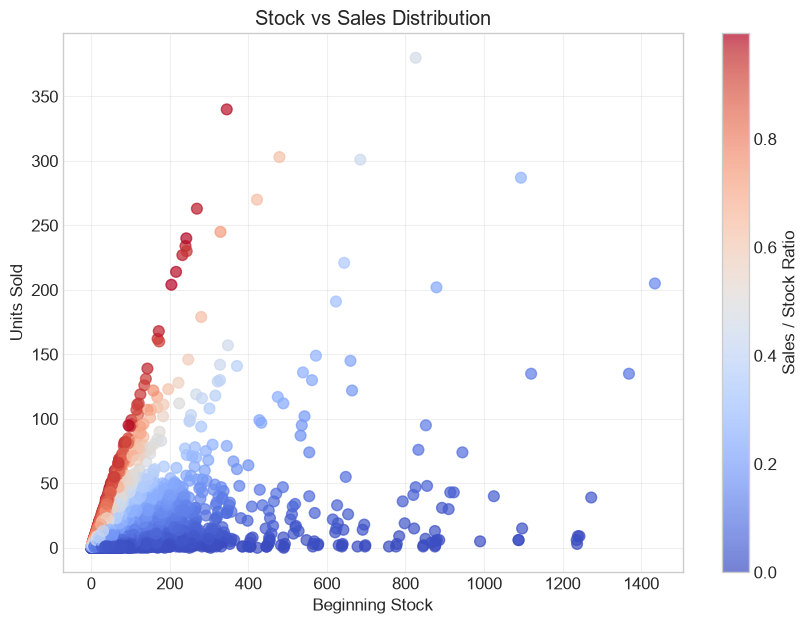

In [15]:
plt.figure(figsize=(10,7))

scatter = plt.scatter(
    df_monthly["beginning_stock"],
    df_monthly["units_sold"],
    c=df_monthly["units_sold"] /
      (df_monthly["beginning_stock"] + 1),
    cmap="coolwarm",
    alpha=0.7,
    s=60
)

plt.xlabel("Beginning Stock")
plt.ylabel("Units Sold")
plt.title("Stock vs Sales Distribution")

plt.grid(alpha=0.3)

plt.colorbar(scatter,label="Sales / Stock Ratio")

plt.show()

## 2. Stock-to-Sales Ratio Distribution

This graph illustrates how efficiently inventory is converted into sales.

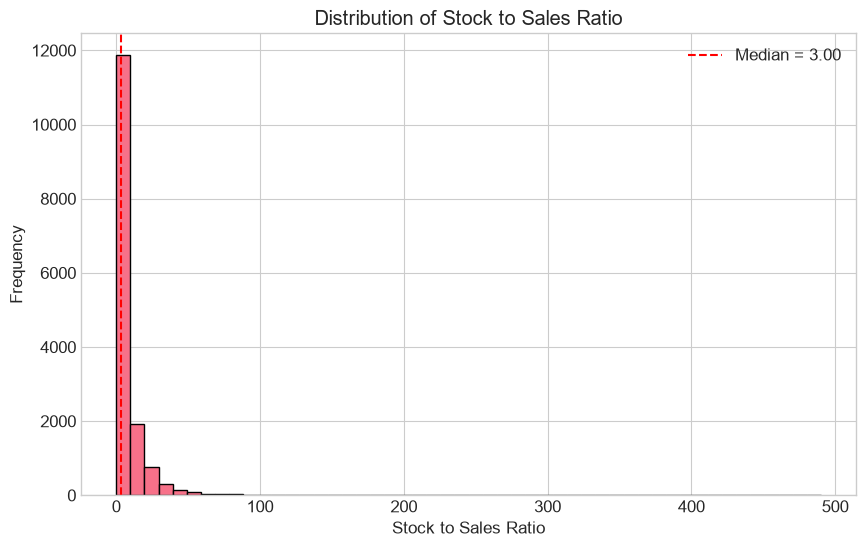

In [16]:
plt.figure(figsize=(10,6))

df_monthly["Stock_to_Sales_Ratio"].hist(
    bins=50,
    edgecolor="black"
)

plt.axvline(
    df_monthly["Stock_to_Sales_Ratio"].median(),
    color="red",
    linestyle="--",
    label=f"Median = {df_monthly['Stock_to_Sales_Ratio'].median():.2f}"
)

plt.xlabel("Stock to Sales Ratio")
plt.ylabel("Frequency")
plt.title("Distribution of Stock to Sales Ratio")

plt.legend()

plt.show()

## 3. Category-wise Stock vs Sales

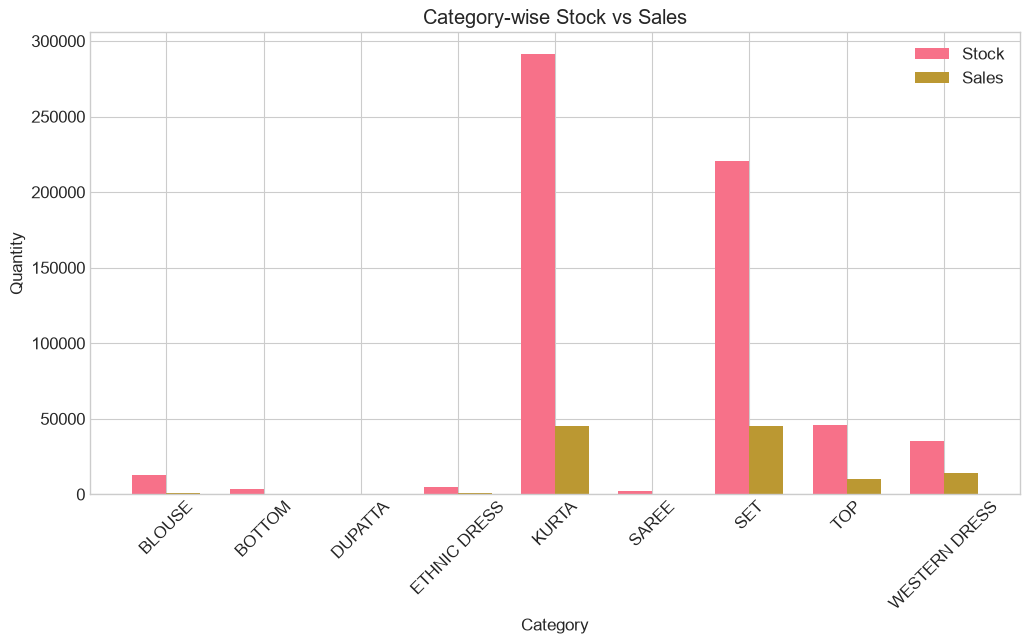

In [17]:
category_perf = df_monthly.groupby("Category").agg({

    "beginning_stock":"sum",
    "units_sold":"sum"

}).reset_index()

category_perf["Sales_Efficiency"] = (

    category_perf["units_sold"]/

    category_perf["beginning_stock"]

)*100

plt.figure(figsize=(12,6))

x=np.arange(len(category_perf))

width=0.35

plt.bar(
    x-width/2,
    category_perf["beginning_stock"],
    width,
    label="Stock"
)

plt.bar(
    x+width/2,
    category_perf["units_sold"],
    width,
    label="Sales"
)

plt.xticks(x,category_perf["Category"],rotation=45)

plt.xlabel("Category")

plt.ylabel("Quantity")

plt.title("Category-wise Stock vs Sales")

plt.legend()

plt.show()

## 4. Average Sales Efficiency by Category

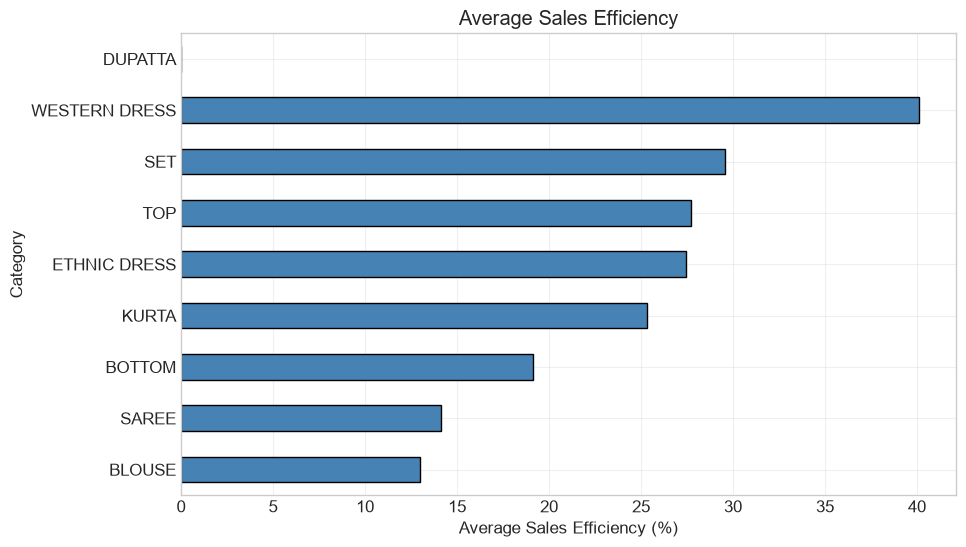

In [18]:
cat_efficiency = (

    df_monthly

    .groupby("Category")["Sales_Efficiency"]

    .mean()

    .sort_values()

)

plt.figure(figsize=(10,6))

cat_efficiency.plot(

    kind="barh",

    color="steelblue",

    edgecolor="black"

)

plt.xlabel("Average Sales Efficiency (%)")

plt.ylabel("Category")

plt.title("Average Sales Efficiency")

plt.grid(alpha=0.3)

plt.show()

## 5. Item Classification Distribution

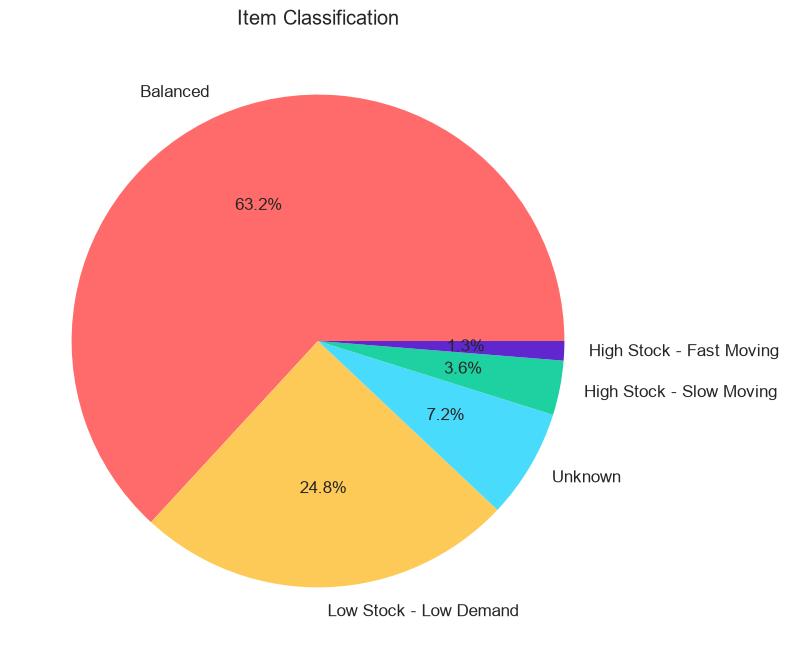

In [19]:
colors = [

"#ff6b6b",

"#feca57",

"#48dbfb",

"#1dd1a1",

"#5f27cd",

"#ff9ff3"

]

df_monthly["Item_Class"].value_counts().plot(

    kind="pie",

    autopct="%1.1f%%",

    figsize=(8,8),

    colors=colors

)

plt.ylabel("")

plt.title("Item Classification")

plt.show()

## 6. Stock vs Sales Density Heatmap

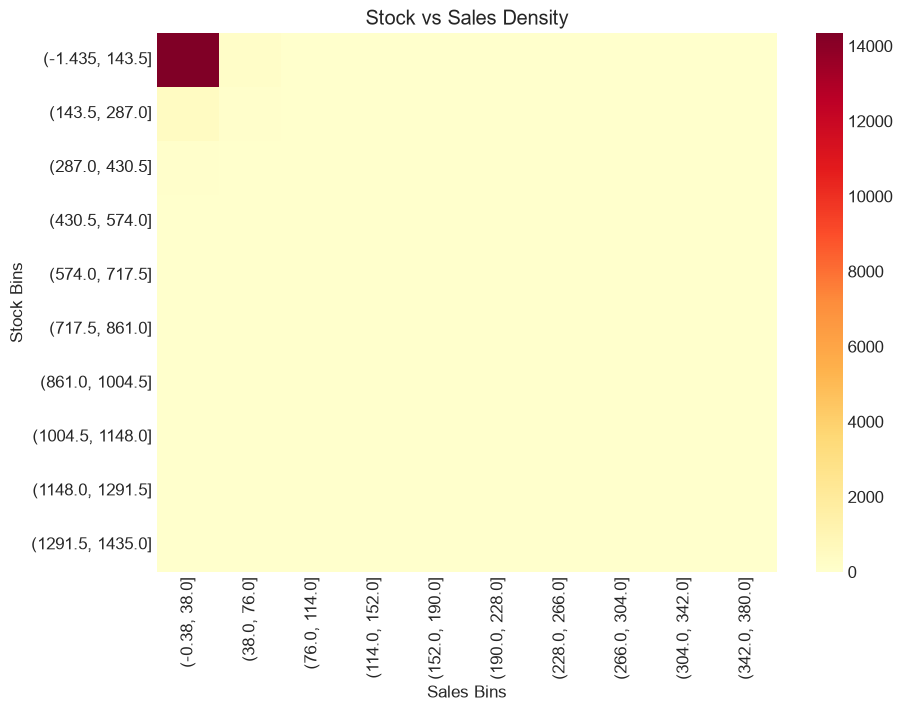

In [20]:
temp=df_monthly.copy()

temp["Stock_Bin"]=pd.cut(
    temp["beginning_stock"],
    bins=10
)

temp["Sales_Bin"]=pd.cut(
    temp["units_sold"],
    bins=10
)

heatmap=temp.groupby(
    ["Stock_Bin","Sales_Bin"]
).size().unstack(fill_value=0)

plt.figure(figsize=(10,7))

sns.heatmap(

    heatmap,

    cmap="YlOrRd"

)

plt.title("Stock vs Sales Density")

plt.xlabel("Sales Bins")

plt.ylabel("Stock Bins")

plt.show()

# Analysis 2 – Geographic Sales Analysis

This section analyzes sales performance across different geographical locations.

The objectives are:

- Identify top-performing cities
- Compare sales among states
- Analyze average order values
- Understand regional demand patterns

## 1. Top 15 Cities by Sales Volume

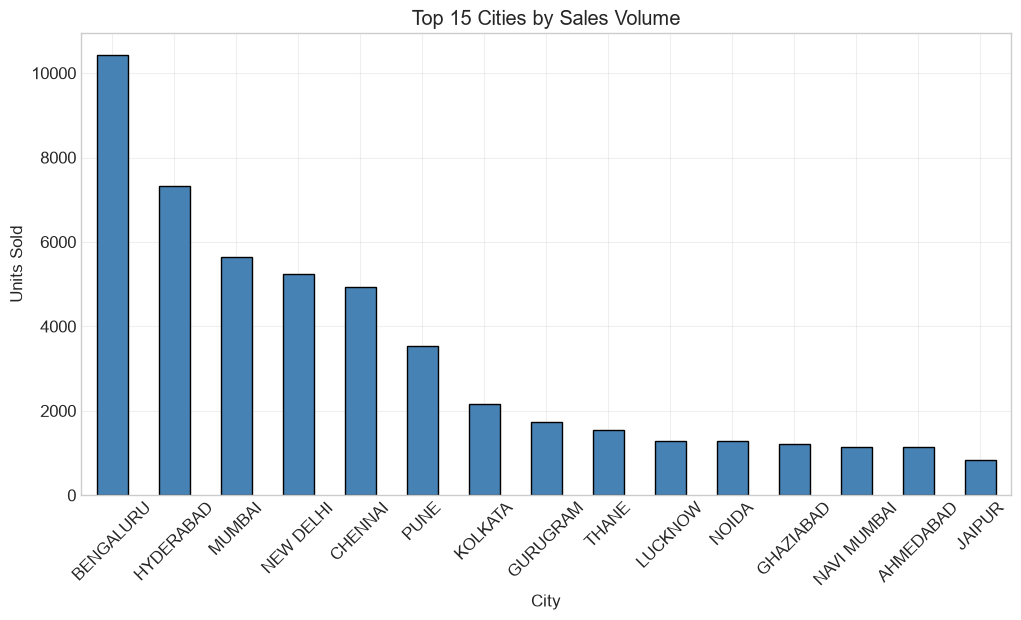

In [21]:
city_sales = (
    df_merged
    .groupby("ship-city")["Qty"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12,6))

city_sales.plot(
    kind="bar",
    color="steelblue",
    edgecolor="black"
)

plt.title("Top 15 Cities by Sales Volume")

plt.xlabel("City")

plt.ylabel("Units Sold")

plt.xticks(rotation=45)

plt.grid(alpha=0.3)

plt.show()

## 2. Sales by State

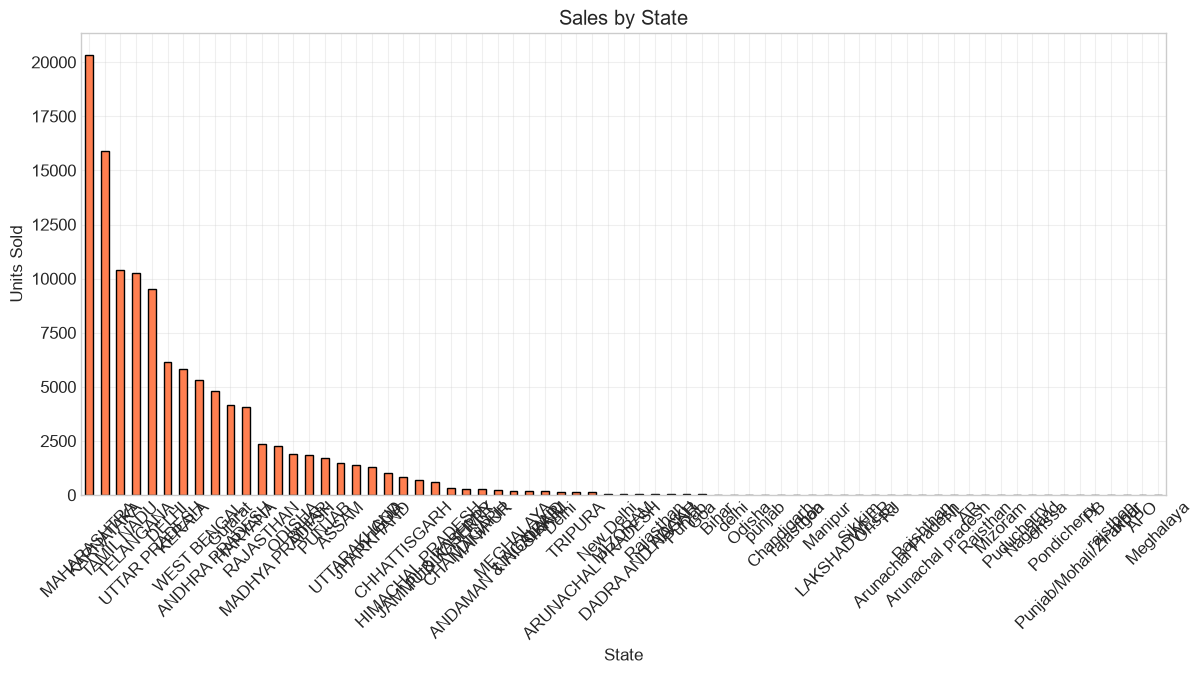

In [22]:
state_sales = (
    df_merged
    .groupby("ship-state")["Qty"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14,6))

state_sales.plot(
    kind="bar",
    color="coral",
    edgecolor="black"
)

plt.title("Sales by State")

plt.xlabel("State")

plt.ylabel("Units Sold")

plt.xticks(rotation=45)

plt.grid(alpha=0.3)

plt.show()

## 3. Average Order Value by City

Average Order Value (AOV) indicates the average revenue generated per unit sold in each city.

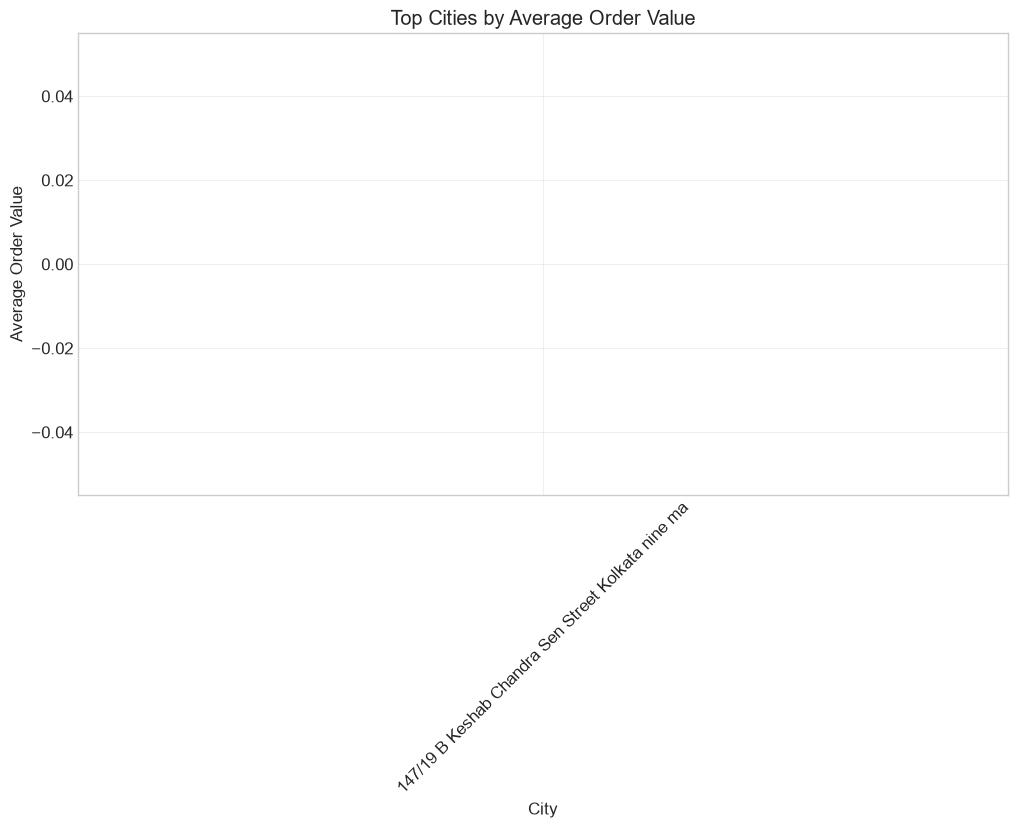

In [23]:
city_performance = (
    df_merged
    .groupby("ship-city")
    .agg({
        "Qty":"sum",
        "Amount":"sum"
    })
    .reset_index()
)

city_performance["Avg_Order_Value"] = (
    city_performance["Amount"] /
    city_performance["Qty"]
)

city_performance = (
    city_performance
    .sort_values(
        "Avg_Order_Value",
        ascending=False
    )
    .head(15)
)

plt.figure(figsize=(12,6))

plt.bar(
    city_performance["ship-city"],
    city_performance["Avg_Order_Value"],
    color="seagreen",
    edgecolor="black"
)

plt.title("Top Cities by Average Order Value")

plt.xlabel("City")

plt.ylabel("Average Order Value")

plt.xticks(rotation=45)

plt.grid(alpha=0.3)

plt.show()

## 4. Monthly Sales by State

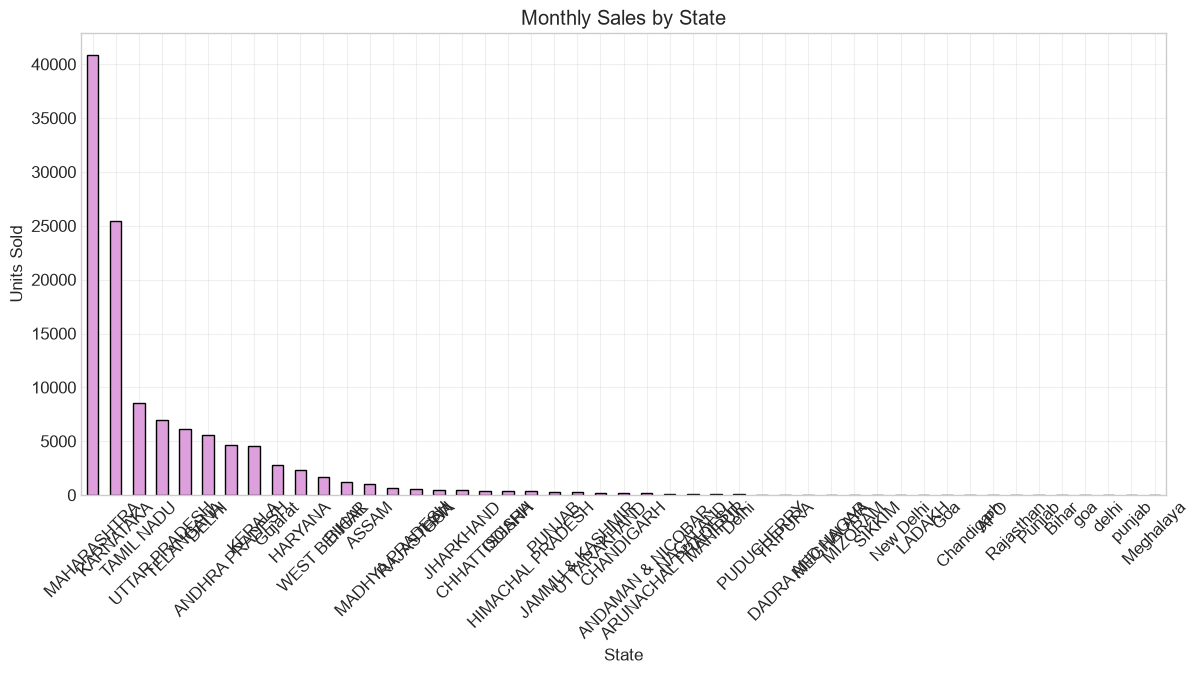

In [24]:
state_perf = (
    df_monthly
    .groupby("ship_state_mode")["units_sold"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14,6))

state_perf.plot(
    kind="bar",
    color="plum",
    edgecolor="black"
)

plt.title("Monthly Sales by State")

plt.xlabel("State")

plt.ylabel("Units Sold")

plt.xticks(rotation=45)

plt.grid(alpha=0.3)

plt.show()

## Geographic Analysis Summary

From the above visualizations we can identify:

- Cities contributing the highest sales volume.
- States generating the greatest demand.
- Cities with the highest average order value.
- Regional differences in monthly product sales.

These insights help determine where inventory should be prioritized and where future demand is likely to increase.

# Analysis 3 – Product Attribute Analysis

This section explores customer purchasing behavior based on product attributes such as Category, Color, and Size.

Objectives:

- Identify the highest selling product categories.
- Discover the most popular colors.
- Analyze size preferences.
- Compare stock against sales by category.
- Evaluate sales efficiency by size.
- Explore the relationship between category and size.

## 1. Category-wise Sales

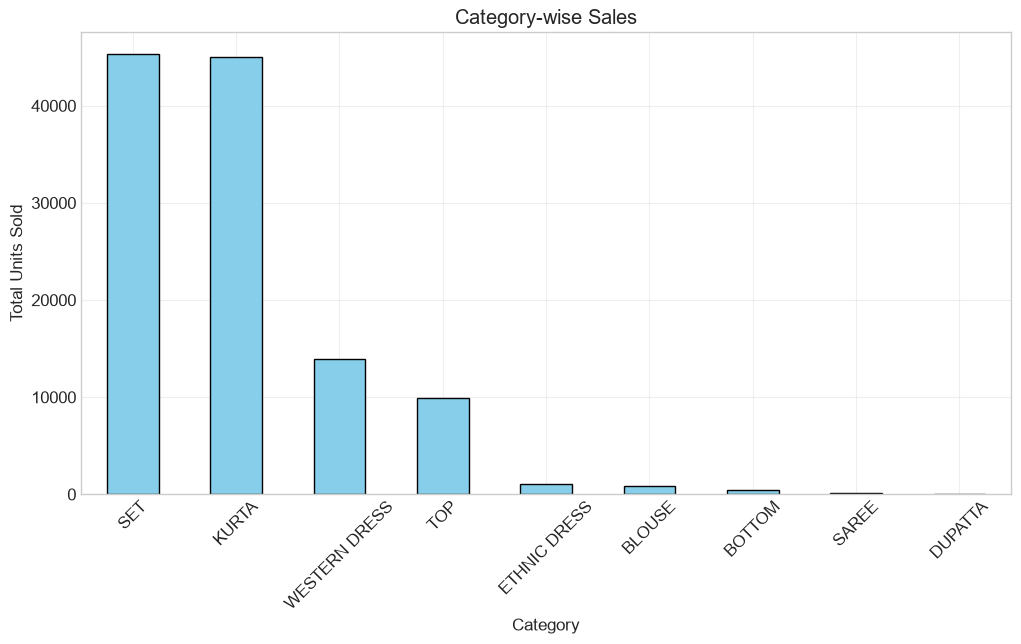

In [25]:
category_sales = (
    df_merged
    .groupby("Category")["Qty"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12,6))

category_sales.plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Category-wise Sales")

plt.xlabel("Category")

plt.ylabel("Total Units Sold")

plt.xticks(rotation=45)

plt.grid(alpha=0.3)

plt.show()

## 2. Color-wise Sales

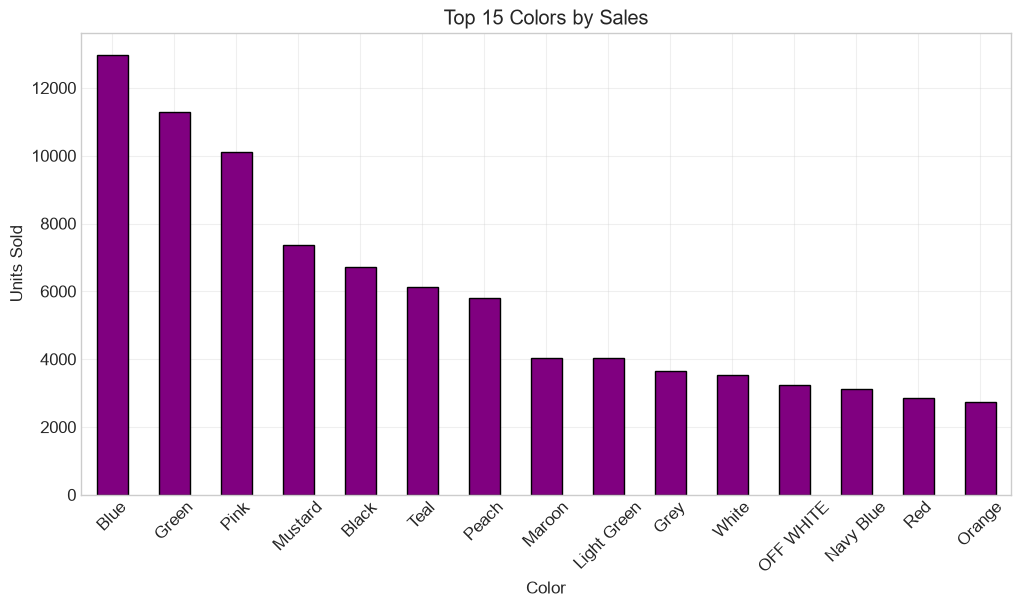

In [26]:
color_sales = (
    df_merged
    .groupby("Color")["Qty"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12,6))

color_sales.plot(
    kind="bar",
    color="purple",
    edgecolor="black"
)

plt.title("Top 15 Colors by Sales")

plt.xlabel("Color")

plt.ylabel("Units Sold")

plt.xticks(rotation=45)

plt.grid(alpha=0.3)

plt.show()

## 3. Size-wise Sales

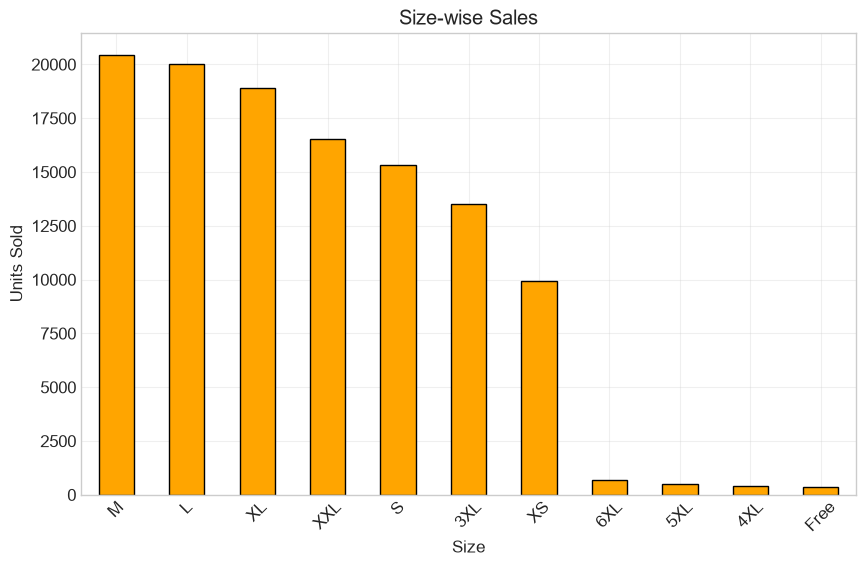

In [27]:
size_sales = (
    df_merged
    .groupby("Size")["Qty"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,6))

size_sales.plot(
    kind="bar",
    color="orange",
    edgecolor="black"
)

plt.title("Size-wise Sales")

plt.xlabel("Size")

plt.ylabel("Units Sold")

plt.xticks(rotation=45)

plt.grid(alpha=0.3)

plt.show()

## 4. Category-wise Stock vs Sales

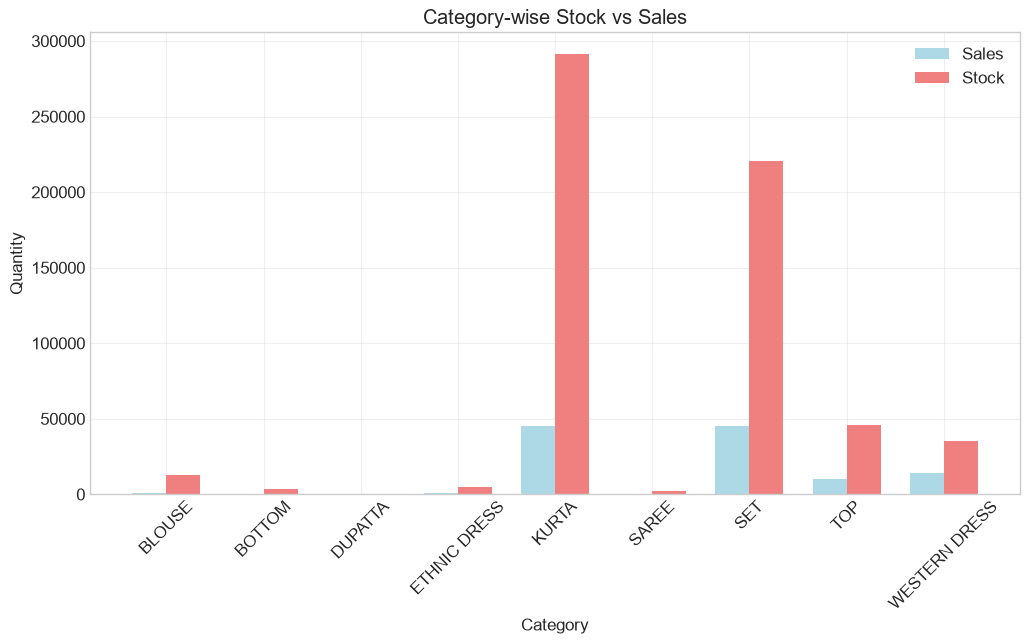

In [28]:
cat_stock_sales = (
    df_monthly
    .groupby("Category")
    .agg({
        "units_sold":"sum",
        "beginning_stock":"sum"
    })
    .reset_index()
)

plt.figure(figsize=(12,6))

x = np.arange(len(cat_stock_sales))

width = 0.35

plt.bar(
    x-width/2,
    cat_stock_sales["units_sold"],
    width,
    label="Sales",
    color="lightblue"
)

plt.bar(
    x+width/2,
    cat_stock_sales["beginning_stock"],
    width,
    label="Stock",
    color="lightcoral"
)

plt.xticks(
    x,
    cat_stock_sales["Category"],
    rotation=45
)

plt.xlabel("Category")

plt.ylabel("Quantity")

plt.title("Category-wise Stock vs Sales")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

## 5. Size-wise Sales Efficiency

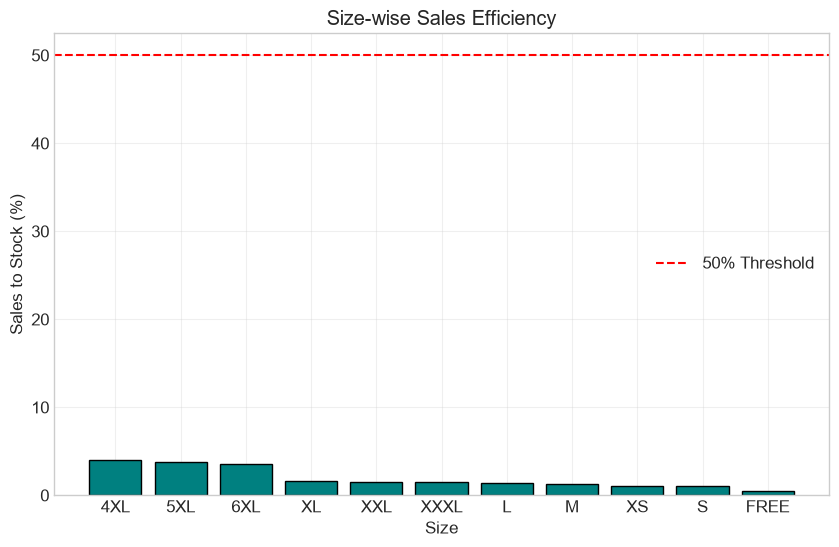

In [29]:
size_stock_sales = (
    df_merged
    .groupby("Size_stock")
    .agg({
        "Qty":"sum",
        "Stock":"sum"
    })
    .reset_index()
)

size_stock_sales["Sales_to_Stock_%"] = (

    size_stock_sales["Qty"] /

    size_stock_sales["Stock"]

) * 100

size_stock_sales = size_stock_sales.sort_values(
    "Sales_to_Stock_%",
    ascending=False
)

plt.figure(figsize=(10,6))

plt.bar(
    size_stock_sales["Size_stock"],
    size_stock_sales["Sales_to_Stock_%"],
    color="teal",
    edgecolor="black"
)

plt.axhline(
    50,
    color="red",
    linestyle="--",
    label="50% Threshold"
)

plt.title("Size-wise Sales Efficiency")

plt.xlabel("Size")

plt.ylabel("Sales to Stock (%)")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

## 6. Category × Size Sales Heatmap

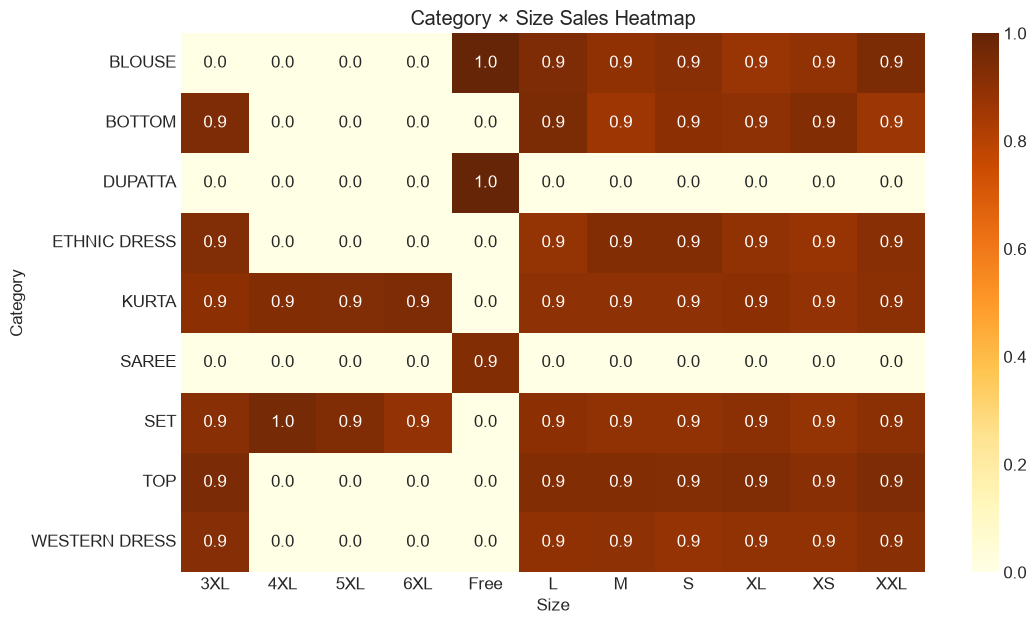

In [30]:
cat_size_heatmap = (
    df_merged
    .groupby(["Category","Size"])["Qty"]
    .mean()
    .unstack(fill_value=0)
)

plt.figure(figsize=(12,7))

sns.heatmap(
    cat_size_heatmap,
    cmap="YlOrBr",
    annot=True,
    fmt=".1f"
)

plt.title("Category × Size Sales Heatmap")

plt.xlabel("Size")

plt.ylabel("Category")

plt.show()

## Product Attribute Analysis Summary

The analysis indicates how customer preferences vary across different product attributes.

Key observations include:

- The highest-selling product categories.
- The most preferred product colors.
- Popular clothing sizes.
- Categories with high inventory but relatively low sales.
- Sales efficiency across different sizes.
- The interaction between category and size in influencing sales.

These findings provide valuable insights for inventory planning and demand forecasting.

# Analysis 4 – Best Selling Attributes

This analysis identifies the highest-performing product attributes based on sales.

Objectives:

- Find the best-selling size in each category.
- Find the best-selling color in each category.
- Identify the best-selling products in different cities.

In [31]:
# Function for color palette

def get_color_palette(n, colormap="tab10"):
    return sns.color_palette(colormap, n)

## 1. Best Selling Size by Category

In [32]:
category_best_size = (
    df_merged
    .groupby(["Category", "Size"])["Qty"]
    .sum()
    .reset_index()
)

category_best_size = (
    category_best_size
    .sort_values(["Category", "Qty"], ascending=[True, False])
    .groupby("Category")
    .first()
    .reset_index()
)

category_best_size

,Category,Size,Qty
0,BLOUSE,Free,211
1,BOTTOM,L,67
2,DUPATTA,Free,3
3,ETHNIC DRESS,XL,173
4,KURTA,L,8043
5,SAREE,Free,152
6,SET,M,8357
7,TOP,XL,1734
8,WESTERN DRESS,L,2546


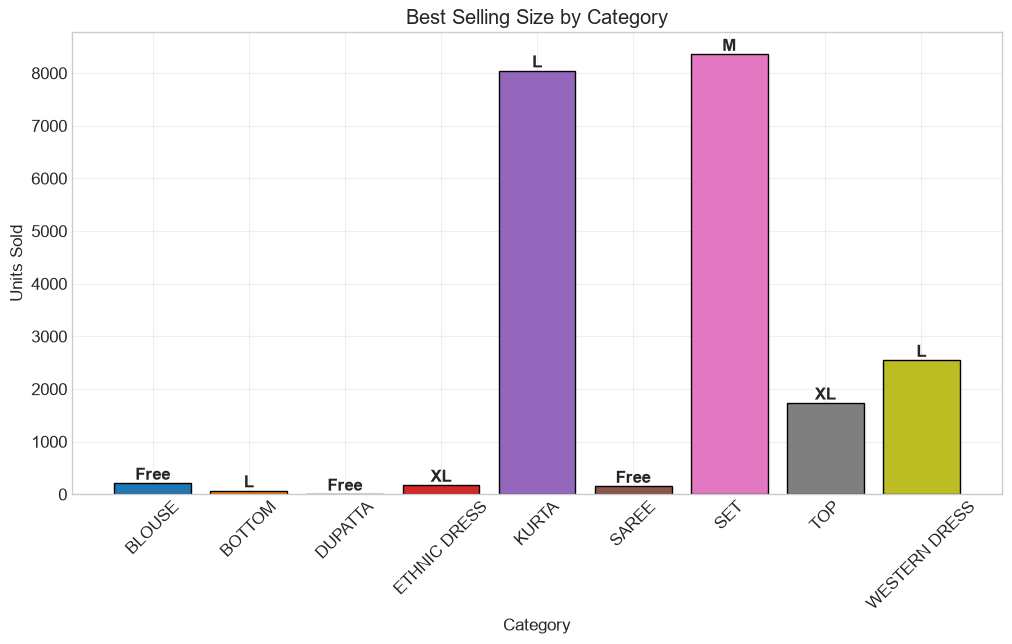

In [33]:
plt.figure(figsize=(12,6))

colors = get_color_palette(len(category_best_size))

bars = plt.bar(
    category_best_size["Category"],
    category_best_size["Qty"],
    color=colors,
    edgecolor="black"
)

for bar, size in zip(bars, category_best_size["Size"]):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        size,
        ha="center",
        va="bottom",
        fontweight="bold"
    )

plt.title("Best Selling Size by Category")

plt.xlabel("Category")

plt.ylabel("Units Sold")

plt.xticks(rotation=45)

plt.grid(alpha=0.3)

plt.show()

## 2. Best Selling Color by Category

In [34]:
category_best_color = (
    df_merged
    .groupby(["Category", "Color"])["Qty"]
    .sum()
    .reset_index()
)

category_best_color = (
    category_best_color
    .sort_values(["Category", "Qty"], ascending=[True, False])
    .groupby("Category")
    .first()
    .reset_index()
)

category_best_color

,Category,Color,Qty
0,BLOUSE,Purple,137
1,BOTTOM,Brown,44
2,ETHNIC DRESS,Mustard,354
3,KURTA,Blue,5445
4,SAREE,Pink,32
5,SET,Pink,5075
6,TOP,Red,1326
7,WESTERN DRESS,Green,4108


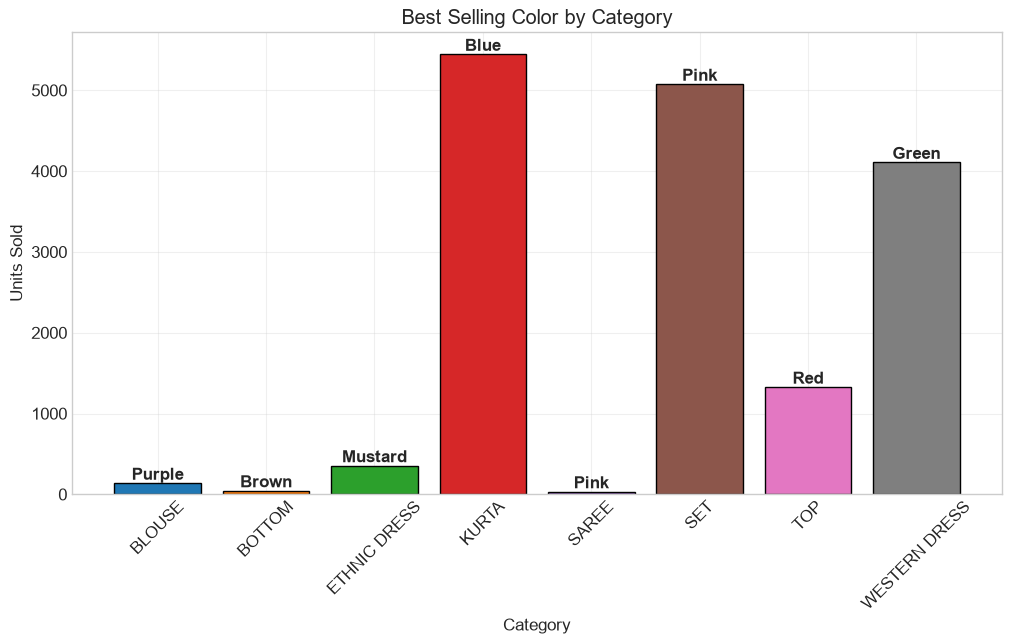

In [35]:
plt.figure(figsize=(12,6))

colors = get_color_palette(len(category_best_color))

bars = plt.bar(
    category_best_color["Category"],
    category_best_color["Qty"],
    color=colors,
    edgecolor="black"
)

for bar, color in zip(bars, category_best_color["Color"]):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        color,
        ha="center",
        va="bottom",
        fontweight="bold"
    )

plt.title("Best Selling Color by Category")

plt.xlabel("Category")

plt.ylabel("Units Sold")

plt.xticks(rotation=45)

plt.grid(alpha=0.3)

plt.show()

## 3. Best Selling Product by City

In [36]:
area_best_items = (
    df_merged
    .groupby(["ship-city", "SKU"])["Qty"]
    .sum()
    .reset_index()
)

area_best_items = (
    area_best_items
    .sort_values(["ship-city", "Qty"], ascending=[True, False])
    .groupby("ship-city")
    .first()
    .reset_index()
)

top_cities = area_best_items.nlargest(10, "Qty")

top_cities

,ship-city,SKU,Qty
776,BENGALURU,JNE3797-KR-L,73
2906,HYDERABAD,JNE3797-KR-L,40
5393,NEW DELHI,J0230-SKD-S,35
4795,MUMBAI,JNE3797-KR-L,31
1466,CHENNAI,JNE3797-KR-L,25
6158,PUNE,JNE3797-KR-L,22
3712,KOLKATA,JNE3405-KR-S,15
7489,Surat,BL017-63BLACK,15
53,AHMEDABAD,JNE3797-KR-L,14
7639,THIRUVANANTHAPURAM,JNE3797-KR-S,13


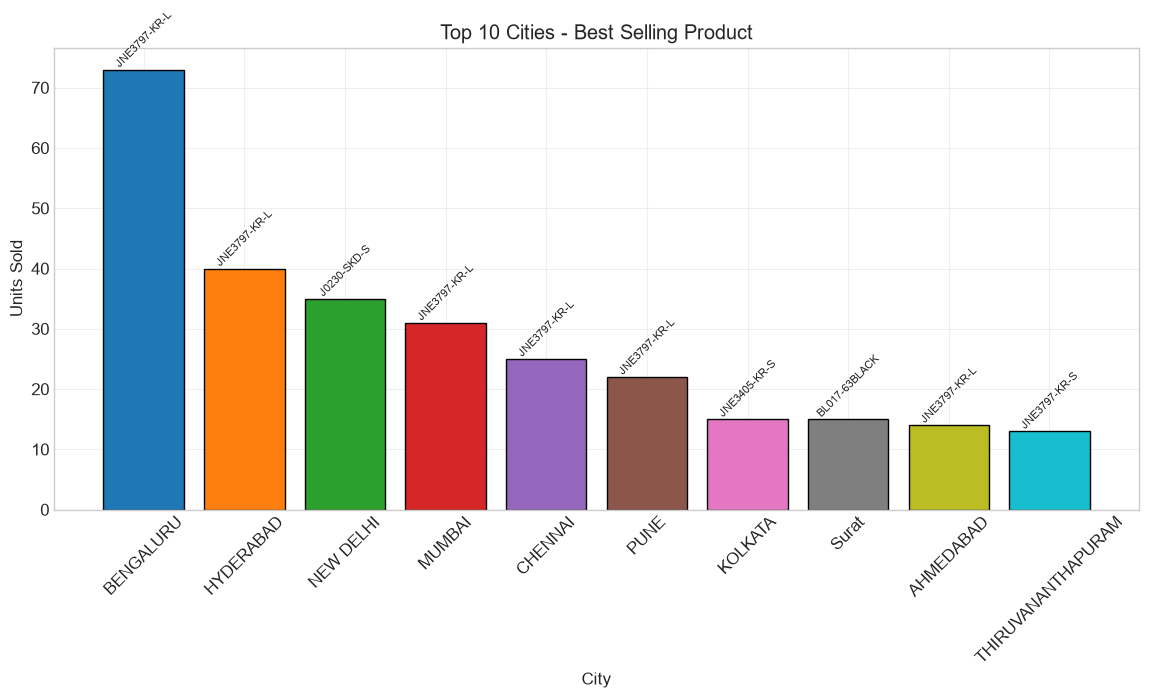

In [37]:
plt.figure(figsize=(14,6))

colors = get_color_palette(len(top_cities))

bars = plt.bar(
    top_cities["ship-city"],
    top_cities["Qty"],
    color=colors,
    edgecolor="black"
)

for bar, sku in zip(bars, top_cities["SKU"]):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        sku,
        ha="center",
        va="bottom",
        rotation=45,
        fontsize=8
    )

plt.title("Top 10 Cities - Best Selling Product")

plt.xlabel("City")

plt.ylabel("Units Sold")

plt.xticks(rotation=45)

plt.grid(alpha=0.3)

plt.show()

## Best Selling Attributes Summary

The analysis reveals:

- The most popular clothing size within each product category.
- The most preferred color within each category.
- The highest-selling products across major cities.

These insights support more effective inventory planning, targeted promotions, and location-specific stocking strategies.

# Analysis 5 – Hypothesis Validation

## Project Hypothesis

**Hypothesis**

Predicting reorder quantities using only historical sales data is not sufficiently accurate. Inventory levels (Beginning Stock) significantly influence sales performance and therefore must be incorporated into demand forecasting models.

This section validates the above hypothesis through multiple statistical and visual analyses.

## 1. Stock vs Sales Classification

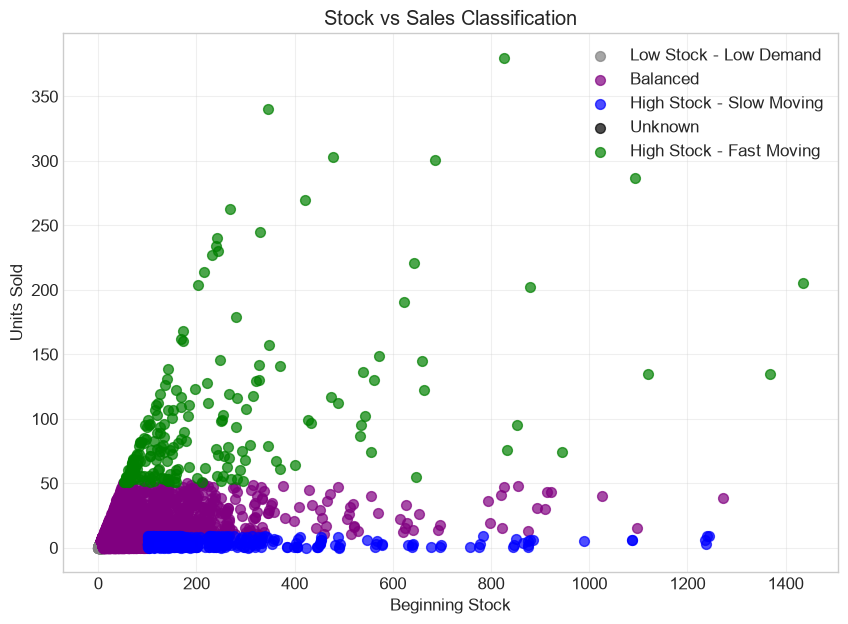

In [39]:
plt.figure(figsize=(10,7))

class_colors = {
    "Sold Out - High Demand":"red",
    "Low Stock - Fast Moving":"orange",
    "High Stock - Slow Moving":"blue",
    "High Stock - Fast Moving":"green",
    "Low Stock - Low Demand":"gray",
    "Balanced":"purple",
    "Unknown":"black"
}

for item_class in df_monthly["Item_Class"].unique():

    mask = df_monthly["Item_Class"] == item_class

    plt.scatter(
        df_monthly.loc[mask,"beginning_stock"],
        df_monthly.loc[mask,"units_sold"],
        color=class_colors.get(item_class,"black"),
        alpha=0.7,
        label=item_class,
        s=50
    )

plt.xlabel("Beginning Stock")

plt.ylabel("Units Sold")

plt.title("Stock vs Sales Classification")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

## 2. Average Stock-to-Sales Ratio by Item Class

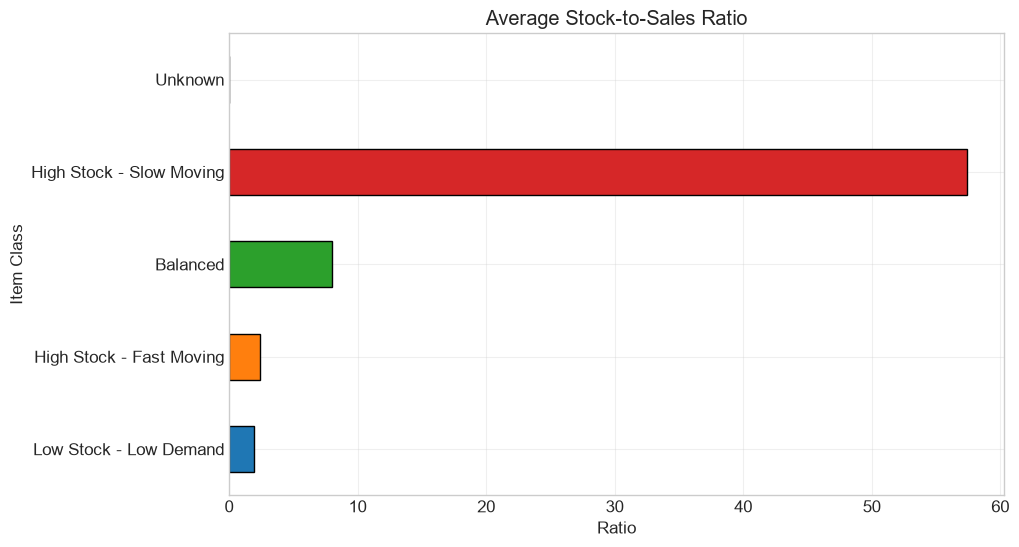

In [40]:
class_ratio = (

    df_monthly

    .groupby("Item_Class")["Stock_to_Sales_Ratio"]

    .mean()

    .sort_values()

)

plt.figure(figsize=(10,6))

class_ratio.plot(

    kind="barh",

    color=sns.color_palette("tab10"),

    edgecolor="black"

)

plt.title("Average Stock-to-Sales Ratio")

plt.xlabel("Ratio")

plt.ylabel("Item Class")

plt.grid(alpha=0.3)

plt.show()

## 3. Stock Minus Sales by Category

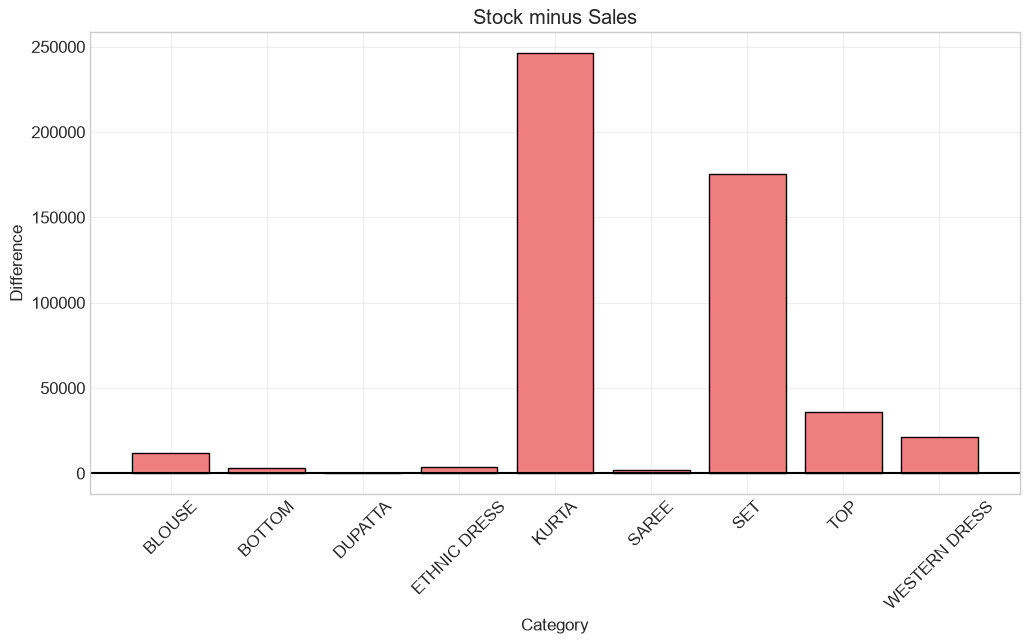

In [41]:
cat_comp = (

    df_monthly

    .groupby("Category")

    .agg({

        "beginning_stock":"sum",

        "units_sold":"sum"

    })

    .reset_index()

)

cat_comp["Stock_Sales_Diff"] = (

    cat_comp["beginning_stock"]

    -

    cat_comp["units_sold"]

)

colors = [

    "lightcoral" if x > 0 else "lightgreen"

    for x in cat_comp["Stock_Sales_Diff"]

]

plt.figure(figsize=(12,6))

plt.bar(

    cat_comp["Category"],

    cat_comp["Stock_Sales_Diff"],

    color=colors,

    edgecolor="black"

)

plt.axhline(

    0,

    color="black"

)

plt.xticks(rotation=45)

plt.title("Stock minus Sales")

plt.xlabel("Category")

plt.ylabel("Difference")

plt.grid(alpha=0.3)

plt.show()

## 4. Correlation Matrix

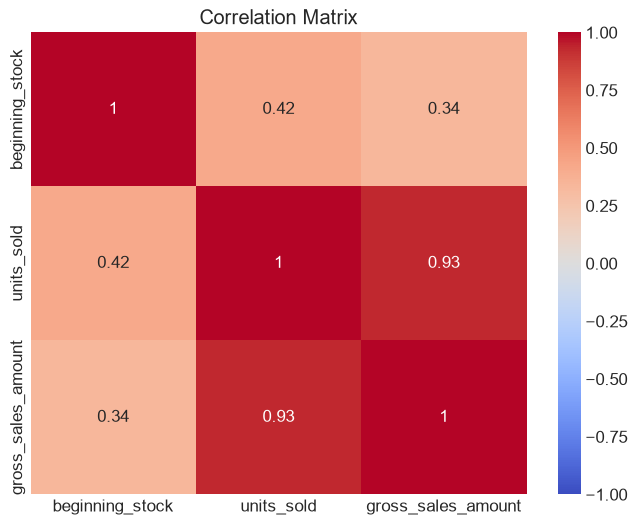

In [42]:
corr_columns = [

    "beginning_stock",

    "units_sold",

    "gross_sales_amount"

]

corr = df_monthly[corr_columns].corr()

plt.figure(figsize=(8,6))

sns.heatmap(

    corr,

    annot=True,

    cmap="coolwarm",

    vmin=-1,

    vmax=1

)

plt.title("Correlation Matrix")

plt.show()

## Hypothesis Validation Summary

The visualizations demonstrate that:

- Beginning stock and units sold are positively related.
- Different inventory classes exhibit distinct sales behaviour.
- Categories with excess stock tend to have lower inventory efficiency.
- Correlation analysis confirms that inventory variables contribute valuable information beyond historical sales.

Therefore, the project hypothesis is **supported**: demand forecasting models should incorporate inventory information alongside historical sales data.

# Export Analysis Results

In [43]:
category_summary = (

    df_monthly

    .groupby("Category")

    .agg({

        "units_sold":["sum","mean","count"],

        "beginning_stock":["sum","mean"],

        "gross_sales_amount":["sum","mean"]

    })

)

category_summary.columns=[

    "Total_Sales",

    "Average_Sales",

    "Number_of_Products",

    "Total_Stock",

    "Average_Stock",

    "Total_Revenue",

    "Average_Revenue"

]

category_summary.to_csv(

    "category_stock_sales_summary.csv"

)

print("Category summary exported.")

Category summary exported.


In [44]:
item_summary = (

    df_monthly

    .groupby("Item_Class")

    .agg({

        "SKU":"count",

        "units_sold":["sum","mean"],

        "beginning_stock":["sum","mean"]

    })

)

item_summary.columns=[

    "Products",

    "Total_Sales",

    "Average_Sales",

    "Total_Stock",

    "Average_Stock"

]

item_summary.to_csv(

    "item_classification_summary.csv"

)

print("Item classification summary exported.")

Item classification summary exported.


In [45]:
geo_summary = (

    df_merged

    .groupby("ship-city")

    .agg({

        "Qty":"sum",

        "Amount":"sum"

    })

    .sort_values(

        "Qty",

        ascending=False

    )

)

geo_summary.to_csv(

    "geographic_sales_summary.csv"

)

print("Geographic summary exported.")

Geographic summary exported.


# Conclusion

This exploratory data analysis provided a comprehensive understanding of sales performance, inventory behaviour, product attributes, and geographical demand.

Major findings include:

- Inventory levels significantly influence product sales.
- Product categories, sizes, and colors exhibit distinct demand patterns.
- Sales vary considerably across different cities and states.
- Fast-moving and slow-moving products can be effectively identified through inventory analysis.
- Historical sales alone are insufficient for accurate reorder prediction.

These findings form the foundation for the next stage of the project, where machine learning models will be developed to forecast demand and recommend optimal reorder quantities.